# 07 · Keterkaitan rumah–kunjungan siang menuju Kota Yogyakarta

**Tahap 1 output aplikatif · Desember 2021–Februari 2022 · WIB**

Pertanyaan: pasangan asal di luar Kota dan tujuan di dalam Kota mana yang paling kuat dalam sampel, dan apakah pola itu bertahan antarbulan?

Analisis memakai data repo yang sudah tersedia. Tidak menambah dataset dan tidak mengestimasi jumlah perjalanan, komuter, atau pengunjung Kota unik.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src' / 'config.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Jalankan notebook dari root repo atau folder notebooks/.')
sys.path.insert(0, str(ROOT / 'src'))
from analyze_daytime_visits import run_analysis
from config import FIGURES, OD_GOOD_MONTHS

pair_month, pairs, quality = run_analysis()
complete = pairs[pairs.complete_months].copy()
TOP_K = 10
DESTINATION_CODE = '34.71.13'  # Umbulharjo; ubah untuk menelusuri tujuan lain
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13})
COLORS = ['#0F766E', '#C2410C', '#2563EB']
MONTH_LABELS = ['Des 2021', 'Jan 2022', 'Feb 2022']
def save(fig, name):
    fig.savefig(FIGURES / f'rq4_{name}.png', bbox_inches='tight', facecolor='white')

## tl;dr

In [2]:
monthly_top = pair_month.loc[pair_month.top3_month]
common_pairs = monthly_top.groupby(['origin_code', 'dest_code']).month.nunique()
common_pairs = common_pairs[common_pairs.eq(len(OD_GOOD_MONTHS))]
stable_labels = [pairs.loc[(pairs.origin_code.eq(o)) & (pairs.dest_code.eq(d)), 'pair_label'].iloc[0]
                 for o, d in common_pairs.index]
leaders = complete.head(3)
bullets = '\n'.join(f'- {r.pair_label}: rata-rata **{r.mean_devices_per_month:,.1f} MAID per bulan**; '
                    f'rate tiga bulan **{r.pooled_visit_rate:.1%}**.'
                    for r in leaders.itertuples())
display(Markdown(
    f'**{len(complete)} dari {len(pairs)} pasangan** terbit pada ketiga bulan dan menjadi kelompok perbandingan utama.\n\n'
    + bullets + '\n\n'
    + f'Pasangan yang berada di tiga terbesar pada **setiap** bulan (urutan dapat berubah): '
    + '; '.join(stable_labels) + '.\n\n'
    + '**Makna:** keterkaitan kunjungan siang pada perangkat yang teramati. Angka tidak menentukan tujuan bekerja, '
      'frekuensi perjalanan, kapasitas transportasi, atau jumlah orang.'))

**329 dari 896 pasangan** terbit pada ketiga bulan dan menjadi kelompok perbandingan utama.

- Banguntapan (Bantul) → Umbulharjo: rata-rata **1,092.7 MAID per bulan**; rate tiga bulan **20.5%**.
- Depok (Sleman) → Gondokusuman: rata-rata **837.3 MAID per bulan**; rate tiga bulan **10.0%**.
- Banguntapan (Bantul) → Kotagede: rata-rata **616.7 MAID per bulan**; rate tiga bulan **11.6%**.

Pasangan yang berada di tiga terbesar pada **setiap** bulan (urutan dapat berubah): Banguntapan (Bantul) → Umbulharjo; Banguntapan (Bantul) → Kotagede; Depok (Sleman) → Gondokusuman.

**Makna:** keterkaitan kunjungan siang pada perangkat yang teramati. Angka tidak menentukan tujuan bekerja, frekuensi perjalanan, kapasitas transportasi, atau jumlah orang.

## Context & Methods

Satu observasi adalah **asal rumah bulanan × tujuan siang × bulan**. MAID dengan rumah di asal dihitung sekali dalam satu pasangan-bulan jika terlihat setidaknya sekali di tujuan pada 08.00–17.59 WIB.

### Key Assumptions

- Scope: semua asal di luar Kota Yogyakarta → setiap kemantren tujuan di dalam Kota; gunakan **kode**, karena JETIS muncul di dua wilayah.
- Hanya Desember–Februari; Maret–April ditandai kualitas OD rendah oleh sumber.
- Seluruh kombinasi wilayah dan bulan dipertahankan. Baris yang tidak diterbitkan tetap **NA**, bukan nol.
- Ranking rata-rata dan pooled rate utama hanya untuk pasangan terbit pada semua tiga bulan. Ini memilih hubungan yang cukup teramati; bukan gambaran lengkap semua hubungan kecil.
- `visit_rate = n_maids / n_homed_maids`: denominator adalah semua MAID dengan rumah bulanan di asal. Periode tiga bulan memakai `sum(n_maids) / sum(n_homed_maids)` pada pasangan yang sama. Ini rate berbobot device-month, bukan rata-rata sederhana rate bulanan dan bukan union MAID unik selama tiga bulan.
- Ranking bulanan berdasarkan jumlah MAID terbit; ties menggunakan minimum rank. Semua ties pada batas ketiga ikut masuk kelompok top-3.
- Jangan menjumlah hitungan/rate berbagai tujuan untuk memperoleh unique visitor tingkat Kota. Perangkat bisa terlihat pada beberapa tujuan.

**Sumber:** `data/processed/od_dec_feb.parquet`, `data/interim/od_homes.parquet`, dan `data/interim/kapanewon_crosswalk.csv`. Dibentuk oleh pipeline repo dari [JogjaPulse v1](https://zenodo.org/records/23157460). Hash input tersimpan di `data/processed/daytime_visits/quality.json`.

## Data

### 1. Cakupan publikasi dan pemeriksaan grain

Cakupan di bawah memakai seluruh 64 × 14 × 3 kemungkinan pasangan-bulan. Baris tidak terbit dapat mencakup hitungan nol atau hitungan kecil yang disembunyikan; nilainya tidak direkonstruksi.

In [3]:
qa_table = pd.DataFrame([
    ['Kemungkinan pasangan-bulan', quality['possible_pair_months']],
    ['Pasangan-bulan terbit', quality['published_pair_months']],
    ['Pasangan-bulan tidak terbit', quality['unpublished_pair_months']],
    ['Kemungkinan pasangan asal–tujuan', quality['possible_pairs']],
    ['Pasangan terbit ketiga bulan', quality['complete_three_month_pairs']],
    ['Baris antarwilayah bernama sama yang tetap dipertahankan', quality['name_collision_pairs_retained']],
], columns=['Pemeriksaan', 'Hasil'])
display(qa_table)
assert not pair_month.duplicated(['month', 'origin_code', 'dest_code']).any()
assert pair_month.loc[~pair_month.published, 'n_maids'].isna().all()
assert pair_month.loc[pair_month.published, 'visit_rate'].between(0, 1).all()

,Pemeriksaan,Hasil
0,Kemungkinan pasangan-bulan,2688
1,Pasangan-bulan terbit,1361
2,Pasangan-bulan tidak terbit,1327
3,Kemungkinan pasangan asal–tujuan,896
4,Pasangan terbit ketiga bulan,329
5,Baris antarwilayah bernama sama yang tetap dip...,3


## Results

### 2. Pasangan dengan rata-rata jumlah perangkat terbesar

Perbandingan di antara pasangan dengan tiga bulan terbit. Rata-rata bulanan mengandung perangkat yang dapat berulang lintas bulan; grafik tidak menjumlah seluruh tujuan menjadi pengunjung Kota.

,Pasangan,Bulan terbit,Mean MAID/bulan,Rate berbobot 3 bulan
0,Banguntapan (Bantul) → Umbulharjo,3,"1,092.7",20.5%
1,Depok (Sleman) → Gondokusuman,3,837.3,10.0%
2,Banguntapan (Bantul) → Kotagede,3,616.7,11.6%
3,Depok (Sleman) → Umbulharjo,3,439.3,5.3%
4,Banguntapan (Bantul) → Gondokusuman,3,391.0,7.3%
5,Depok (Sleman) → Jetis,3,322.3,3.9%
6,Gamping (Sleman) → Jetis,3,300.7,5.3%
7,Sleman (Sleman) → Gondomanan,3,297.0,13.0%
8,Sewon (Bantul) → Umbulharjo,3,262.0,10.2%
9,Ngaglik (Sleman) → Gondokusuman,3,257.0,4.1%


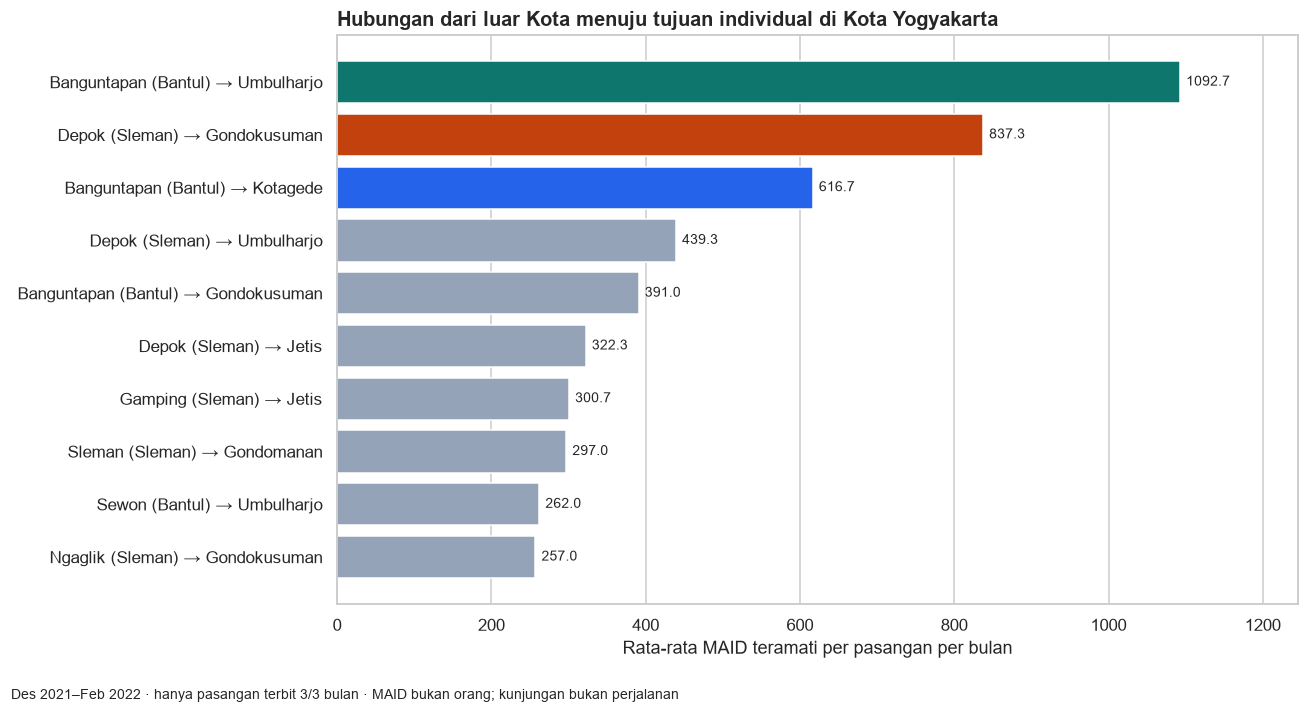

In [4]:
top = complete.head(TOP_K)
display(top[['pair_label', 'months_published', 'mean_devices_per_month', 'pooled_visit_rate']]
        .rename(columns={'pair_label': 'Pasangan', 'months_published': 'Bulan terbit',
                         'mean_devices_per_month': 'Mean MAID/bulan', 'pooled_visit_rate': 'Rate berbobot 3 bulan'})
        .style.format({'Mean MAID/bulan': '{:,.1f}', 'Rate berbobot 3 bulan': '{:.1%}'}))
fig, ax = plt.subplots(figsize=(12, 6.5))
plot = top.iloc[::-1]
bar_colors = [COLORS[list(top.index).index(i)] if list(top.index).index(i) < 3 else '#94A3B8' for i in plot.index]
bars = ax.barh(plot.pair_label, plot.mean_devices_per_month, color=bar_colors)
ax.bar_label(bars, fmt='%.1f', padding=4, fontsize=9)
ax.set_xlim(0, top.mean_devices_per_month.max() * 1.14)
ax.set_xlabel('Rata-rata MAID teramati per pasangan per bulan')
ax.set_title('Hubungan dari luar Kota menuju tujuan individual di Kota Yogyakarta', loc='left')
ax.grid(axis='y', visible=False)
fig.text(.01, .01, 'Des 2021–Feb 2022 · hanya pasangan terbit 3/3 bulan · MAID bukan orang; kunjungan bukan perjalanan', fontsize=9)
fig.tight_layout(rect=(0, .04, 1, 1))
save(fig, 'top_pairs')
plt.show()

### 3. Apakah rate pasangan utama konsisten antarbulan?

Pakai tiga pasangan teratas menurut volume rata-rata, lalu tampilkan rate setiap bulan. Range antarbulan di sini adalah variasi yang teramati, **bukan interval kepercayaan**. Perubahan panel dapat tetap memengaruhi rate.

month,2021-12,2022-01,2022-02
pair_label,,,
Banguntapan (Bantul) → Kotagede,11.4%,12.7%,10.5%
Banguntapan (Bantul) → Umbulharjo,20.3%,23.5%,17.1%
Depok (Sleman) → Gondokusuman,8.2%,10.7%,11.7%


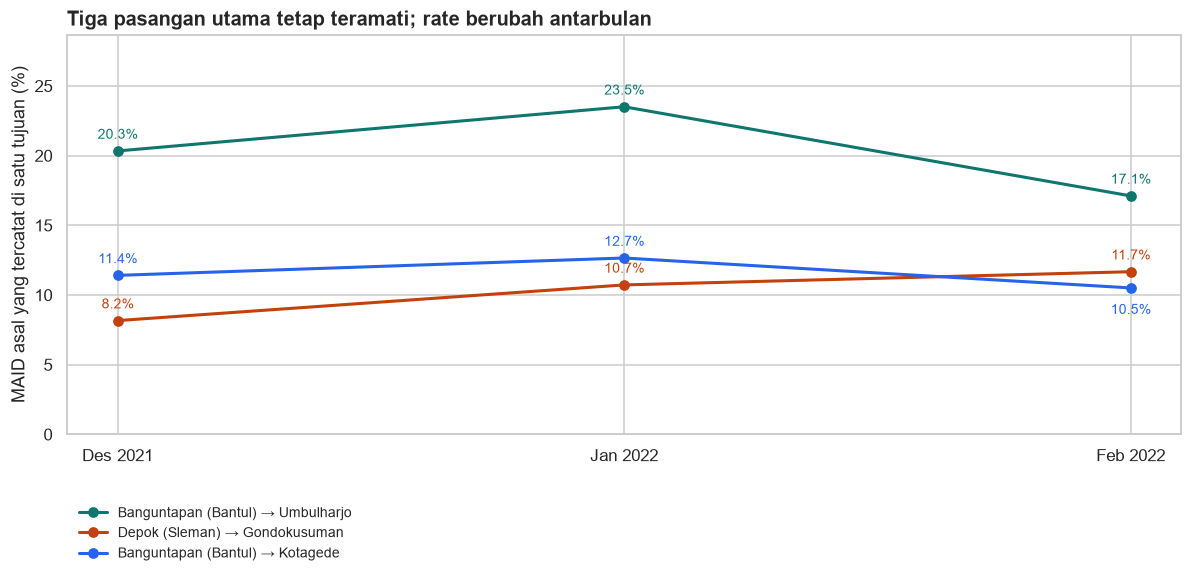

In [5]:
selected = top.head(3)[['origin_code', 'dest_code', 'pair_label']]
rates = pair_month.merge(selected, on=['origin_code', 'dest_code'], how='inner', validate='many_to_one')
rate_table = rates.pivot(index='pair_label', columns='month', values='visit_rate').reindex(columns=OD_GOOD_MONTHS)
display(rate_table.style.format('{:.1%}'))
fig, ax = plt.subplots(figsize=(11, 5.5))
for color, row in zip(COLORS, selected.itertuples()):
    curve = rates[rates.origin_code.eq(row.origin_code) & rates.dest_code.eq(row.dest_code)].set_index('month').reindex(OD_GOOD_MONTHS)
    ax.plot(range(3), curve.visit_rate.astype(float) * 100, marker='o', lw=2, color=color, label=row.pair_label)
    for i, v in enumerate(curve.visit_rate):
        offset = -17 if (i == 2 and row.dest_code == '34.71.14') else 8
        ax.annotate(f'{v:.1%}', (i, float(v) * 100), xytext=(0, offset), textcoords='offset points', ha='center', fontsize=9, color=color)
ax.set_xticks(range(3), MONTH_LABELS)
ax.set_ylim(0, float(rates.visit_rate.max()) * 100 * 1.22)
ax.set_ylabel('MAID asal yang tercatat di satu tujuan (%)')
ax.set_title('Tiga pasangan utama tetap teramati; rate berubah antarbulan', loc='left')
ax.legend(loc='upper left', bbox_to_anchor=(0, -.15), frameon=False, fontsize=9)
fig.tight_layout()
save(fig, 'monthly_rates')
plt.show()

### 4. Volume besar dan rate tinggi menjawab pertanyaan berbeda

Pilih satu tujuan. Kedua panel menampilkan **asal yang sama dalam urutan sama**: kiri jumlah perangkat per bulan; kanan pooled visit rate. Denominator setiap asal berbeda dan ditampilkan pada tabel. Pemilihan kode tujuan dapat diubah di sel setup.

,origin_kapanewon,origin_kab_kota,observed_device_months,origin_device_months,pooled_visit_rate
0,BANGUNTAPAN,BANTUL,3278,16001,20.5%
3,DEPOK,SLEMAN,1318,25048,5.3%
8,SEWON,BANTUL,786,7713,10.2%
10,GAMPING,SLEMAN,756,16964,4.5%
19,KASIHAN,BANTUL,595,16420,3.6%
38,NGAGLIK,SLEMAN,383,18798,2.0%
51,BERBAH,SLEMAN,304,3259,9.3%
65,MLATI,SLEMAN,270,9702,2.8%


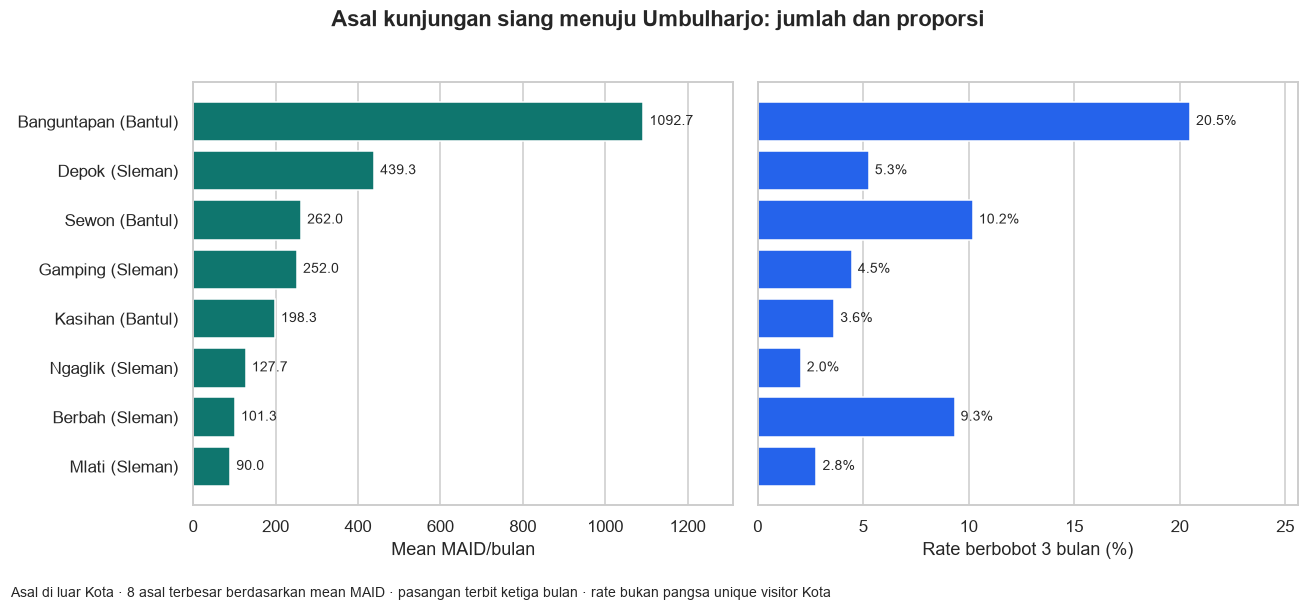

In [6]:
destination = complete[complete.dest_code.eq(DESTINATION_CODE)].head(8).copy()
assert not destination.empty, 'Tujuan tidak memiliki pasangan lengkap; pilih kode lain.'
dest_name = destination.dest_kapanewon.iloc[0].title()
display(destination[['origin_kapanewon', 'origin_kab_kota', 'observed_device_months', 'origin_device_months', 'pooled_visit_rate']]
        .style.format({'pooled_visit_rate': '{:.1%}'}))
p = destination.iloc[::-1]
labels = p.origin_kapanewon.str.title() + ' (' + p.origin_kab_kota.str.title() + ')'
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
a = axes[0].barh(labels, p.mean_devices_per_month, color='#0F766E')
axes[0].bar_label(a, fmt='%.1f', padding=4, fontsize=9)
axes[0].set_xlabel('Mean MAID/bulan')
axes[0].set_xlim(0, p.mean_devices_per_month.max() * 1.2)
b = axes[1].barh(labels, p.pooled_visit_rate.astype(float) * 100, color='#2563EB')
axes[1].bar_label(b, labels=[f'{v:.1%}' for v in p.pooled_visit_rate], padding=4, fontsize=9)
axes[1].set_xlabel('Rate berbobot 3 bulan (%)')
axes[1].set_xlim(0, float(p.pooled_visit_rate.max()) * 100 * 1.25)
for ax in axes: ax.grid(axis='y', visible=False)
fig.suptitle(f'Asal kunjungan siang menuju {dest_name}: jumlah dan proporsi', weight='bold')
fig.text(.01, .01, 'Asal di luar Kota · 8 asal terbesar berdasarkan mean MAID · pasangan terbit ketiga bulan · rate bukan pangsa unique visitor Kota', fontsize=9)
fig.tight_layout(rect=(0, .04, 1, .96))
save(fig, 'destination_origins')
plt.show()

### 5. Telusuri satu angka hingga denominatornya

Contoh Desember untuk Banguntapan→Umbulharjo. Pemeriksaan ini membantu memastikan numerator dan denominator berasal dari asal dan bulan yang sama.

In [7]:
example = pair_month.loc[pair_month.month.eq('2021-12') & pair_month.origin_code.eq('34.02.12')
                         & pair_month.dest_code.eq('34.71.13')].iloc[0]
manual_rate = int(example.n_maids) / int(example.n_homed_maids)
assert np.isclose(manual_rate, example.visit_rate)
display(Markdown(f'**{int(example.n_maids):,} / {int(example.n_homed_maids):,} = {manual_rate:.2%}**. '
                 'Artinya MAID rumah Banguntapan yang tercatat setidaknya sekali di Umbulharjo pada siang hari bulan itu.'))

**1,394 / 6,856 = 20.33%**. Artinya MAID rumah Banguntapan yang tercatat setidaknya sekali di Umbulharjo pada siang hari bulan itu.

## Takeaways

- Pasangan yang konsisten berada di kelompok teratas dapat menjadi sasaran awal survei/observasi keterhubungan wilayah. Data tidak menentukan kebutuhan rute atau kapasitas angkutan.
- Tinjau jumlah perangkat **dan** rate. Jumlah besar dapat berkaitan dengan besarnya sampel asal; rate menjawab proporsi dalam sampel asal.
- Cakupan belum lengkap: pasangan kecil yang disembunyikan tetap unknown. Ranking utama dibatasi pasangan terbit ketiga bulan dan tidak dianggap mewakili seluruh hubungan DIY.
- Rumah MAID adalah estimasi bulanan, perangkat tidak sama dengan orang, kunjungan tidak sama dengan trip atau commuting. Jangan menjumlah antar tujuan untuk menghitung pengunjung Kota unik.
- Tahap berikutnya untuk output kedua adalah analisis Ramadan dengan pemeriksaan coverage dan sensitivitas yang terpisah. Notebook ini tidak menarik kesimpulan Ramadan dari OD bulanan.

**Reproduksi:** jalankan pipeline pada README, lalu `python src/analyze_daytime_visits.py`, dan jalankan notebook dari atas ke bawah. Tes semantik: `python -m unittest discover -s tests -v`.